=== Perbandingan Hasil Evaluasi ===
   Metrik  Logistic Regression  Random Forest
 Accuracy             0.988304       0.935673
Precision             0.984375       0.920635
   Recall             0.984375       0.906250
 F1-Score             0.984375       0.913386


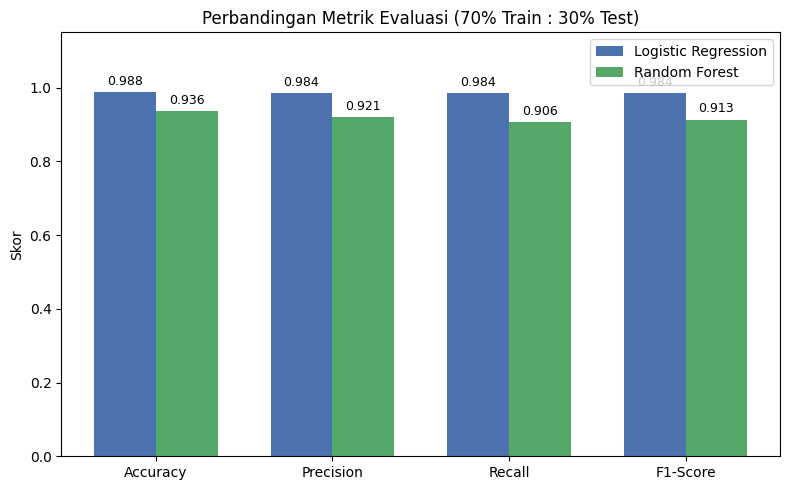

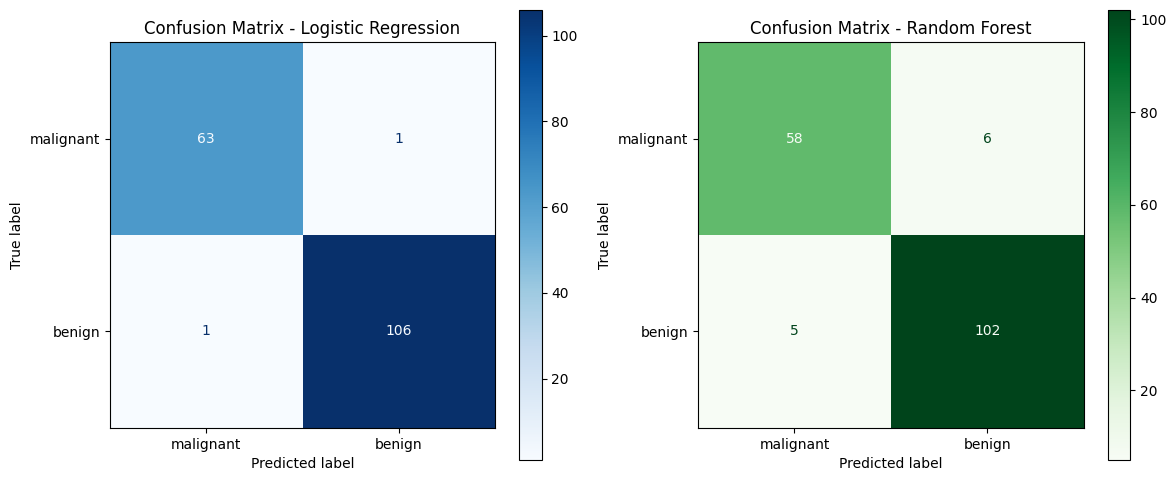

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load dataset Breast Cancer
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target  # 0 = malignant (ganas), 1 = benign (jinak)

# 2. Pembagian dataset: 70% training dan 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Normalisasi fitur untuk Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Melatih model Logistic Regression dan Random Forest Classifier
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# 4. Prediksi pada data testing (30%)
y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_rf = rf_model.predict(X_test)

# 5. Hitung metrik evaluasi (pos_label=0 agar fokus mendeteksi kanker ganas/malignant)
metrics_data = {
    "Metrik": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Logistic Regression": [
        accuracy_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_lr, pos_label=0),
        recall_score(y_test, y_pred_lr, pos_label=0),
        f1_score(y_test, y_pred_lr, pos_label=0),
    ],
    "Random Forest": [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf, pos_label=0),
        recall_score(y_test, y_pred_rf, pos_label=0),
        f1_score(y_test, y_pred_rf, pos_label=0),
    ],
}

df_results = pd.DataFrame(metrics_data)
print("=== Perbandingan Hasil Evaluasi ===")
print(df_results.to_string(index=False))

# 6. Simpan grafik perbandingan metrik -> evaluation_results.png
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(df_results["Metrik"]))
width = 0.35

rects1 = ax.bar(
    x - width / 2,
    df_results["Logistic Regression"],
    width,
    label="Logistic Regression",
    color="#4C72B0",
)
rects2 = ax.bar(
    x + width / 2,
    df_results["Random Forest"],
    width,
    label="Random Forest",
    color="#55A868",
)

ax.set_ylabel("Skor")
ax.set_title("Perbandingan Metrik Evaluasi (70% Train : 30% Test)")
ax.set_xticks(x)
ax.set_xticklabels(df_results["Metrik"])
ax.set_ylim(0, 1.15)
ax.legend()

for rect in rects1 + rects2:
  height = rect.get_height()
  ax.annotate(
      f"{height:.3f}",
      xy=(rect.get_x() + rect.get_width() / 2, height),
      xytext=(0, 3),
      textcoords="offset points",
      ha="center",
      va="bottom",
      fontsize=9,
  )

plt.tight_layout()
plt.savefig("evaluation_results.png", dpi=300)
plt.show()

# 7. Simpan gambar Confusion Matrix -> confusion_matrix.png
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr, display_labels=data.target_names, ax=axes[0], cmap="Blues"
)
axes[0].set_title("Confusion Matrix - Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf, display_labels=data.target_names, ax=axes[1], cmap="Greens"
)
axes[1].set_title("Confusion Matrix - Random Forest")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

Perbandingan Algoritma: Berdasarkan hasil pengujian pada 30% data testing, Logistic Regression memberikan hasil klasifikasi yang lebih unggul dibandingkan Random Forest Classifier (terutama pada nilai Accuracy, Recall, dan F1-Score untuk mendeteksi sel kanker ganas/malignant).

Mengapa Accuracy Saja Tidak Cukup dalam Klasifikasi Kanker? : Karena dalam diagnosis medis seperti kanker payudara, jumlah data pasien sehat dan pasien kanker sering kali tidak seimbang, dan setiap jenis kesalahan memiliki dampak yang berbeda. Accuracy hanya mengukur total tebakan benar secara keseluruhan tanpa membedakan jenis kesalahannya. Kesalahan paling fatal dalam deteksi kanker adalah False Negative (pasien sebenarnya mengidap kanker ganas, tetapi diprediksi sehat/jinak oleh model), karena pasien akan terlambat mendapatkan penanganan medis. Oleh karena itu, metrik Recall (kemampuan model menangkap seluruh kasus kanker yang sebenarnya) dan Precision (ketepatan prediksi positif agar tidak menimbulkan kepanikan akibat salah diagnosis) jauh lebih krusial dibandingkan Accuracy semata.